# Behavior-IF: phát hiện hành vi bất thường từ bản ghi flow của Suricata

In [ ]:
%pip install -q numpy==2.5.3 scikit-learn==1.9.1 scipy joblib pandas matplotlib gdown

## 1. Cấu hình

In [2]:
import os, math, time
import numpy as np
import pandas as pd
import joblib
import gdown
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import IsolationForest as SkIF
from scipy.stats import spearmanr
from isolationforest import IsolationForest, explain_str

print("numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)
if (np.__version__, sklearn.__version__) != ("2.5.3", "1.9.1"):
    print("Chú ý: khác phiên bản lúc chốt số liệu (numpy 2.5.3, scikit-learn 1.9.1), cây có thể khác đôi chút.")

SEED, N_TREES, MAX_SAMPLES = 3, 300, 1024
TRAIN_FRAC = 0.7          # mỗi chiều: 70% luồng đầu để huấn luyện, phần sau để kiểm định
FPR_MAX_VAL = 0.002       # FPR kiểm định tối đa khi chọn ngưỡng
Q_GRID = [0.0005, 0.001, 0.0015, 0.002, 0.003, 0.004, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03]
WINDOW_MIN, WINDOW_HOP_MIN = 30, 15
INCOMPLETE = {"syn_sent", "syn_recv"}
MODEL_OUT = "net_if_model.joblib"
DATA_DIR = "data"
DRIVE_URL = ""   # liên kết thư mục dữ liệu trên Google Drive (chia sẻ "Bất kỳ ai có liên kết"); để trống nếu đã chép dữ liệu vào data/
TEP = ["flow_normal.csv", "flow_test.csv", "flow_runs.csv"]


def data_path(fn):
    return os.path.join(DATA_DIR, fn)


if not all(os.path.exists(data_path(f)) for f in TEP):
    if not DRIVE_URL:
        raise FileNotFoundError("Chưa có dữ liệu: chép các tệp CSV vào thư mục data/ hoặc điền DRIVE_URL.")
    gdown.download_folder(url=DRIVE_URL, output=DATA_DIR, quiet=False, resume=True)

numpy 2.5.3 | scikit-learn 1.9.1 | pandas 3.0.5


## 2. Dữ liệu

In [3]:
COLS = ["start", "end", "src", "dst", "dport", "proto", "bytes_toserver", "bytes_toclient",
        "tcp_state", "direction", "peer_zone"]
DT = {"proto": str, "tcp_state": str}
EPOCH0 = pd.Timestamp("1970-01-01", tz="UTC")


def epoch(s):
    return (pd.to_datetime(s, format="ISO8601", utc=True) - EPOCH0).dt.total_seconds().values


def ngay(t):
    return pd.Timestamp(t, unit="s", tz="UTC").tz_convert("Asia/Ho_Chi_Minh").strftime("%d/%m %H:%M")


t0 = time.time()
N = pd.read_csv(data_path("flow_normal.csv"), usecols=COLS, dtype=DT, keep_default_na=False)
N["_t"] = epoch(N["start"])
CUT = {d: float(np.quantile(N.loc[N["direction"] == d, "_t"], TRAIN_FRAC)) for d in ("out", "in")}
N["part"] = np.where(N["_t"] < N["direction"].map(CUT), "train", "val")

tong = N.groupby(["direction", "part"]).agg(luong=("src", "size"), tu=("_t", "min"), den=("_t", "max"))
tong["tu"] = tong["tu"].map(ngay)
tong["den"] = tong["den"].map(ngay)
print(tong.to_string())
print(f"Đọc trong {time.time() - t0:.0f}s")


def svc_keys(d):
    """Khóa dịch vụ: chiều|vùng đầu kia|giao thức|cổng."""
    return d["direction"] + "|" + d["peer_zone"] + "|" + d["proto"].str.upper() + "|" + d["dport"].astype(str)


RAR = svc_keys(N[N["part"] == "train"]).value_counts()
RAR_COUNTS, RAR_TOTAL = RAR.to_dict(), int(RAR.sum())


def rarity(key):
    return -math.log10((RAR_COUNTS.get(key, 0) + 1) / (RAR_TOTAL + 1))


print(f"Bảng độ hiếm: {len(RAR_COUNTS)} khóa dịch vụ trên {RAR_TOTAL:,} luồng huấn luyện")
print((RAR / RAR_TOTAL * 100).round(3).head(8).to_string())

                   luong           tu          den
direction part                                    
in        train    77090  12/10 14:07  19/10 06:35
          val      33039  19/10 06:35  25/10 23:58
out       train  2232084  15/09 00:00  27/09 16:26
          val     956608  27/09 16:26  10/10 22:56
Đọc trong 23s


Bảng độ hiếm: 19 khóa dịch vụ trên 2,309,174 luồng huấn luyện
out|ext|TCP|443      86.107
out|ext|UDP|443       7.810
in|ext|TCP|80         3.338
out|ext|TCP|80        0.925
out|ext|UDP|3478      0.887
out|ext|UDP|19302     0.877
out|ext|TCP|4545      0.026
out|ext|TCP|3478      0.012


## 3. Đặc trưng

In [4]:
FEATS = ["log_n_conn", "sqrt_mb_out", "log_bytes_in", "frac_out", "log_throughput",
         "log_peak_cpm", "periodicity", "uniformity", "log_n_ports", "frac_incomplete", "svc_rarity"]
FEATS_IF = ["sqrt_mb_out", "frac_out", "log_throughput", "log_peak_cpm",
            "periodicity", "uniformity", "log_n_ports", "svc_rarity"]
IDX_IF = [FEATS.index(f) for f in FEATS_IF]


def _cv(x):
    """Hệ số biến thiên: độ lệch chuẩn / trung bình."""
    m = x.mean() if len(x) else 0.0
    return float(x.std() / m) if m > 0 else 0.0


def _peak_per_min(st):
    """Số kết nối nhiều nhất trong một khung 60 giây."""
    if len(st) == 0:
        return 0
    hi = np.searchsorted(st, st + 60.0, side="right")
    return int((hi - np.arange(len(st))).max())


def feature_vector(st, bts, btc, dur, dports, inc, rar):
    """11 đặc trưng của một cặp máy trong một cửa sổ; mỗi tham số là một mảng theo luồng."""
    order = np.argsort(st, kind="stable")
    st, bts, btc, dur = st[order], bts[order], btc[order], dur[order]
    n = len(st)
    byte_out, byte_in = float(bts.sum()), float(btc.sum())
    byte_all, dur_all = byte_out + byte_in, float(dur.sum())
    gaps = np.diff(st)
    v = {
        "log_n_conn": math.log1p(n),
        "sqrt_mb_out": math.sqrt(byte_out / 1e6),
        "log_bytes_in": math.log1p(byte_in),
        "frac_out": byte_out / byte_all if byte_all > 0 else 0.0,
        "log_throughput": math.log1p(byte_all / dur_all) if dur_all > 0 else 0.0,
        "log_peak_cpm": math.log1p(_peak_per_min(st)),
        "periodicity": math.log1p(len(gaps)) * max(0.0, 1.0 - _cv(gaps)) if len(gaps) >= 3 else 0.0,
        "uniformity": math.log1p(n - 1) * max(0.0, 1.0 - _cv(bts + btc)) if n >= 3 else 0.0,
        "log_n_ports": math.log1p(len(set(dports.tolist()))),
        "frac_incomplete": float(inc.mean()),
        "svc_rarity": float(rar.mean()),
    }
    return [v[f] for f in FEATS]


def rar_of(d):
    keys = svc_keys(d)
    table = {k: rarity(k) for k in keys.unique()}
    return keys.map(table).to_numpy(float)


def windows(d):
    """Gom luồng theo (bên khởi tạo, bên nhận, cửa sổ 30 phút) trên hai lưới lệch nhau 15 phút."""
    start, end = epoch(d["start"]), epoch(d["end"])
    cols = {"st": start,
            "bts": d["bytes_toserver"].to_numpy(float),
            "btc": d["bytes_toclient"].to_numpy(float),
            "dur": np.clip(end - start, 0, None),
            "dport": d["dport"].to_numpy(),
            "inc": d["tcp_state"].str.lower().isin(INCOMPLETE).to_numpy(float),
            "rar": rar_of(d)}
    src, dst, dirn = d["src"].to_numpy(), d["dst"].to_numpy(), d["direction"].to_numpy()
    run = d["run_id"].to_numpy() if "run_id" in d else np.full(len(d), "", object)

    keys, feats = [], []
    for off in range(0, WINDOW_MIN * 60, WINDOW_HOP_MIN * 60):
        bucket = ((start - off) // (WINDOW_MIN * 60)).astype("int64")
        gid = pd.factorize(pd.MultiIndex.from_arrays([src, dst, bucket]))[0]
        order = np.argsort(gid, kind="stable")
        g = gid[order]
        lo = np.r_[0, np.flatnonzero(np.diff(g)) + 1]
        hi = np.r_[lo[1:], len(g)]
        for a, z in zip(lo, hi):
            ix = order[a:z]
            feats.append(feature_vector(*(cols[c][ix] for c in ("st", "bts", "btc", "dur", "dport", "inc", "rar"))))
            runs = sorted({r for r in run[ix] if r})
            keys.append((src[ix[0]], dst[ix[0]], dirn[ix[0]], int(bucket[ix[0]]), off, len(ix),
                         float(start[ix].min()), "|".join(runs)))

    K = pd.DataFrame(keys, columns=["src", "dst", "direction", "bucket", "off", "n_conn", "t0", "runs"])
    F = pd.DataFrame(np.array(feats, float).reshape(len(K), -1), columns=FEATS)
    return pd.concat([K, F], axis=1)


t0 = time.time()
W = {}
for d in ("out", "in"):
    for p in ("train", "val"):
        W[(d, p)] = windows(N[(N["direction"] == d) & (N["part"] == p)])
del N
for k, v in W.items():
    assert np.isfinite(v[FEATS].values).all(), f"Đặc trưng {k} có NaN/inf"
print({f"{d}/{p}": len(v) for (d, p), v in W.items()}, f"| {time.time() - t0:.0f}s")
print(W[("out", "train")][FEATS].describe().T[["mean", "std", "min", "max"]].round(3).to_string())

{'out/train': 956732, 'out/val': 457570, 'in/train': 1756, 'in/val': 854} | 102s


                  mean    std    min     max
log_n_conn       1.500  0.603  0.693   5.318
sqrt_mb_out      0.120  0.141  0.007   5.568
log_bytes_in     9.127  3.442  0.000  19.154
frac_out         0.371  0.249  0.011   1.000
log_throughput   5.021  2.018  0.000  12.768
log_peak_cpm     1.367  0.466  0.693   4.043
periodicity      0.015  0.110  0.000   1.942
uniformity       0.291  0.499  0.000   4.263
log_n_ports      0.695  0.026  0.693   1.386
frac_incomplete  0.327  0.429  0.000   1.000
svc_rarity       0.172  0.329  0.065   5.886


## 4. Huấn luyện hai tham chiếu (chiều ra, chiều vào)

In [5]:
def fit_ref(X):
    """Học một tham chiếu trên X (đủ 11 cột); rừng chỉ nhận các cột FEATS_IF đã chuẩn hóa."""
    mu = X.mean(0)
    sd = X.std(0)
    sd = np.where(sd < 1e-9, 1.0, sd)
    Z = ((X - mu) / sd)[:, IDX_IF]
    own = IsolationForest(n_estimators=N_TREES, max_samples=MAX_SAMPLES, random_state=SEED).fit(Z)
    sk = SkIF(n_estimators=N_TREES, max_samples=min(MAX_SAMPLES, len(Z)), random_state=SEED).fit(Z)
    med = np.median(X, 0)
    mad = np.median(np.abs(X - med), 0)
    scale = np.where(mad > 1e-9, 1.4826 * mad, sd)
    return {"own": own, "sk": sk, "mu": mu, "sd": sd, "med": med, "scale": scale,
            "s_tr": own.anomaly_score(Z), "s_sk": -sk.score_samples(Z)}


def score(ref, X, which="own"):
    Z = ((np.asarray(X, float) - ref["mu"]) / ref["sd"])[:, IDX_IF]
    if which == "own":
        return ref["own"].anomaly_score(Z)
    return -ref["sk"].score_samples(Z)


t0 = time.time()
X_out = W[("out", "train")][FEATS].values
REF = {"out": fit_ref(X_out)}

mau = W[("out", "train")].sample(n=len(W[("in", "train")]), random_state=SEED)
X_in = np.vstack([W[("in", "train")][FEATS].values, mau[FEATS].values])
REF["in"] = fit_ref(X_in)
print(f"Chiều ra: {len(X_out):,} cửa sổ | chiều vào: {len(W[('in', 'train')]):,} cửa sổ + "
      f"{len(mau):,} cửa sổ chiều ra | {time.time() - t0:.0f}s")

Chiều ra: 956,732 cửa sổ | chiều vào: 1,756 cửa sổ + 1,756 cửa sổ chiều ra | 116s


## 5. Chọn ngưỡng trên tập kiểm định

In [6]:
def canh_bao(K, mask):
    """Số cảnh báo: mỗi (bên khởi tạo, bên nhận, khung 30 phút) có cửa sổ bị gắn cờ tính một lần."""
    k = K[np.asarray(mask, bool)]
    khung = (k["t0"] // (WINDOW_MIN * 60)).astype("int64")
    return len(set(zip(k["src"], k["dst"], khung)))


SEL = {}
for d in ("out", "in"):
    V = W[(d, "val")]
    s_val = score(REF[d], V[FEATS].values)
    gio = (V["t0"].max() - V["t0"].min()) / 3600
    rows = []
    for q in Q_GRID:
        thr = float(np.quantile(REF[d]["s_tr"], 1 - q))
        flag = s_val > thr
        rows.append({"SCORE_Q": q, "Ngưỡng": round(thr, 4), "FPR kiểm định (%)": round(100 * flag.mean(), 3),
                     "Cảnh báo nhầm/giờ": round(canh_bao(V, flag) / gio, 2)})
    T = pd.DataFrame(rows)
    dat = T[T["FPR kiểm định (%)"] <= 100 * FPR_MAX_VAL]
    assert len(dat), f"Tham chiếu {d}: không có SCORE_Q nào đạt FPR kiểm định ≤ {100 * FPR_MAX_VAL}%"
    q = float(dat["SCORE_Q"].max())
    SEL[d] = {"q": q, "thr": float(np.quantile(REF[d]["s_tr"], 1 - q)),
              "thr_sk": float(np.quantile(REF[d]["s_sk"], 1 - q))}
    print(f"\nTham chiếu chiều {'ra' if d == 'out' else 'vào'}: {len(V):,} cửa sổ kiểm định trong {gio:.0f} giờ")
    print(T.to_string(index=False))
    print(f">> SCORE_Q = {q} | ngưỡng tự cài {SEL[d]['thr']:.4f} | ngưỡng scikit-learn {SEL[d]['thr_sk']:.4f}")


Tham chiếu chiều ra: 457,570 cửa sổ kiểm định trong 319 giờ
 SCORE_Q  Ngưỡng  FPR kiểm định (%)  Cảnh báo nhầm/giờ
  0.0005  0.7042              0.070               0.66
  0.0010  0.6844              0.141               1.27
  0.0015  0.6742              0.237               2.03
  0.0020  0.6654              0.322               2.77
  0.0030  0.6536              0.467               3.94
  0.0040  0.6464              0.592               4.94
  0.0050  0.6391              0.716               5.95
  0.0075  0.6265              0.991               8.13
  0.0100  0.6159              1.230              10.21
  0.0150  0.5991              1.732              14.15
  0.0200  0.5862              2.168              17.59
  0.0300  0.5545              3.158              25.53
>> SCORE_Q = 0.001 | ngưỡng tự cài 0.6844 | ngưỡng scikit-learn 0.6847

Tham chiếu chiều vào: 854 cửa sổ kiểm định trong 161 giờ
 SCORE_Q  Ngưỡng  FPR kiểm định (%)  Cảnh báo nhầm/giờ
  0.0005  0.7127              0.000     

## 6. Kiểm thử

In [7]:
t0 = time.time()
X = pd.read_csv(data_path("flow_test.csv"), usecols=COLS + ["label", "run_id", "source"], dtype=DT,
                keep_default_na=False)
RUNS = pd.read_csv(data_path("flow_runs.csv"), keep_default_na=False)

# Phần CTU-13 chấm riêng ở mục 6.3; các mục khác dùng phần lab
XC = X[X["source"] == "ctu13"].drop(columns="source")
RUNS_C = RUNS[RUNS["source"] == "ctu13"]
X = X[X["source"] == "lab"].drop(columns="source")
RUNS = RUNS[RUNS["source"] == "lab"].reset_index(drop=True)
print(X.groupby(["direction", "label"]).size().to_string())
X = X[X["label"] != "unknown"]


def cham(XF, dirs=("out", "in")):
    """Gom cửa sổ, chấm bằng tham chiếu của từng chiều và so với ngưỡng."""
    WT = pd.concat([windows(XF[XF["direction"] == d]) for d in dirs], ignore_index=True)
    WT["score"] = np.nan
    WT["score_sk"] = np.nan
    for d in dirs:
        m = (WT["direction"] == d).values
        WT.loc[m, "score"] = score(REF[d], WT.loc[m, FEATS].values)
        WT.loc[m, "score_sk"] = score(REF[d], WT.loc[m, FEATS].values, "sk")
    WT["thr"] = WT["direction"].map({d: SEL[d]["thr"] for d in SEL})
    WT["pred"] = WT["score"] > WT["thr"]
    WT["attack"] = WT["runs"] != ""
    return WT


WT = cham(X)
print(f"Cửa sổ kiểm thử: {len(WT):,} (tấn công {int(WT['attack'].sum()):,}) | {time.time() - t0:.0f}s")


def bang_ket_qua(WT):
    """Recall theo hành vi, tính theo cửa sổ và theo lượt."""
    hit = {r for rs in WT.loc[WT["pred"], "runs"] for r in rs.split("|") if r}
    R = RUNS.assign(phat_hien=RUNS["run_id"].isin(hit))
    hanh_vi = dict(zip(RUNS["run_id"], RUNS["behavior"]))
    tc = WT[WT["attack"]].assign(behavior=lambda x: x["runs"].str.split("|").str[0].map(hanh_vi))
    B = tc.groupby("behavior").agg(cua_so=("pred", "size"), cua_so_bat=("pred", "sum"))
    B["phu_cua_so_%"] = (100 * B["cua_so_bat"] / B["cua_so"]).round(2)
    L = R.groupby("behavior").agg(luot=("phat_hien", "size"), luot_bat=("phat_hien", "sum"))
    B = B.join(L)
    B["phu_luot_%"] = (100 * B["luot_bat"] / B["luot"]).round(2)
    B.loc["TỔNG"] = [B["cua_so"].sum(), B["cua_so_bat"].sum(), round(100 * B["cua_so_bat"].sum() / B["cua_so"].sum(), 2),
                     B["luot"].sum(), B["luot_bat"].sum(), round(100 * B["luot_bat"].sum() / B["luot"].sum(), 2)]
    return B.astype({"cua_so": int, "cua_so_bat": int, "luot": int, "luot_bat": int}), R


B, R_det = bang_ket_qua(WT)
print("\nRecall theo hành vi:")
print(B.to_string())
for d in ("out", "in"):
    hl = WT[(WT["direction"] == d) & ~WT["attack"]]
    gio = (hl["t0"].max() - hl["t0"].min()) / 3600
    print(f"Chiều {'ra' if d == 'out' else 'vào'}: FPR kiểm thử {100 * hl['pred'].mean():.3f}% "
          f"({int(hl['pred'].sum())}/{len(hl):,} cửa sổ), {canh_bao(hl, hl['pred']) / gio:.2f} cảnh báo nhầm/giờ")
TP = int((WT["pred"] & WT["attack"]).sum())
FP = int((WT["pred"] & ~WT["attack"]).sum())
print(f"Precision theo cửa sổ: {100 * TP / max(TP + FP, 1):.2f}%")
print("Lượt bị bỏ sót:", R_det.loc[~R_det["phat_hien"], ["run_id", "behavior", "src_host", "dst_host", "n_flows"]]
      .to_string(index=False))

direction  label  
in         attack     1298476
           normal       22037
out        attack      121843
           normal      952325
           unknown         20


Cửa sổ kiểm thử: 423,544 (tấn công 959) | 92s

Recall theo hành vi:
                  cua_so  cua_so_bat  phu_cua_so_%  luot  luot_bat  phu_luot_%
behavior                                                                      
auth_mgmt            179         179        100.00   118       118      100.00
beacon_even          148         138         93.24    59        59      100.00
beacon_irregular     157         148         94.27    44        44      100.00
download             154         145         94.16   101       100       99.01
exfil                114         114        100.00    85        85      100.00
flood_in              11          11        100.00     3         3      100.00
scan_in                5           5        100.00     2         2      100.00
scan_mgmt            165         165        100.00   109       109      100.00
web_in                26          26        100.00    11        11      100.00
TỔNG                 959         931         97.08   532       

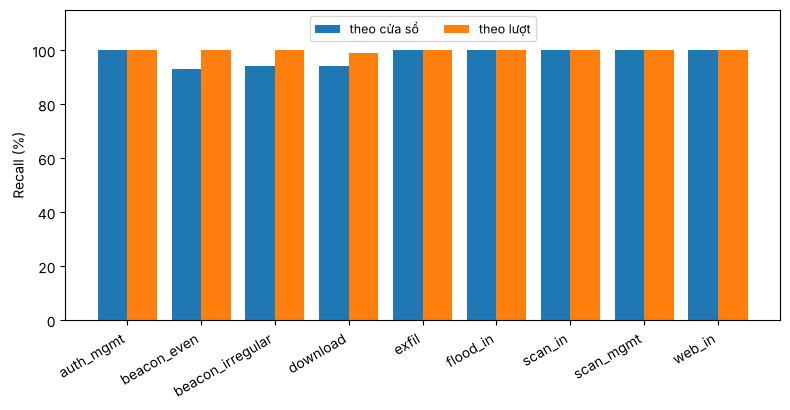

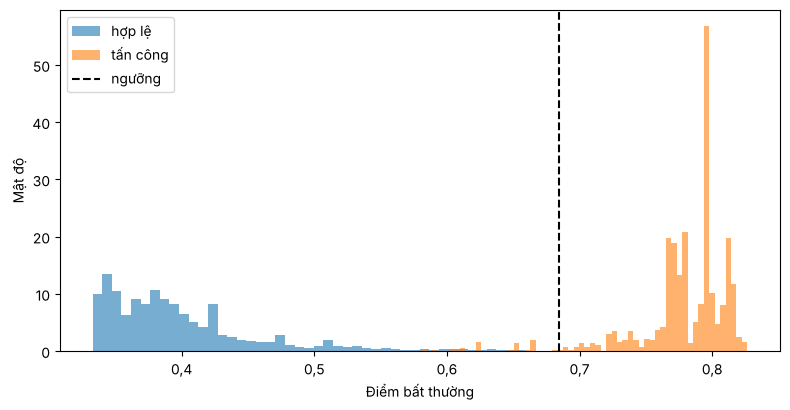

In [8]:
from matplotlib.ticker import FuncFormatter


def so(v, n=1):
    """Số thập phân dùng dấu phẩy như trong báo cáo."""
    return f"{v:.{n}f}".replace(".", ",")


# Hai hình rời như trong báo cáo; hình đồng thời được ghi vào docs/ để README dùng.
os.makedirs("docs", exist_ok=True)

# Recall theo hành vi, tính theo cửa sổ và theo lượt
b = B.drop("TỔNG")
x = np.arange(len(b))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, b["phu_cua_so_%"], 0.4, label="theo cửa sổ")
ax.bar(x + 0.2, b["phu_luot_%"], 0.4, label="theo lượt")
ax.set_xticks(x)
ax.set_xticklabels(b.index, rotation=30, ha="right")
ax.set_ylim(0, 115)
ax.set_ylabel("Recall (%)")
ax.legend(loc="upper center", ncol=2, fontsize=9)
plt.tight_layout()
fig.savefig("docs/behavior_if_recall.png", dpi=220)
plt.show()

# Phân bố điểm của cửa sổ chiều ra trên tập kiểm thử
ra = WT["direction"] == "out"
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(WT.loc[ra & ~WT["attack"], "score"], bins=60, alpha=0.6, density=True, label="hợp lệ")
ax.hist(WT.loc[ra & WT["attack"], "score"], bins=60, alpha=0.6, density=True, label="tấn công")
ax.axvline(SEL["out"]["thr"], color="k", ls="--", label="ngưỡng")
ax.set_xlabel("Điểm bất thường")
ax.set_ylabel("Mật độ")
ax.legend()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: so(v)))
plt.tight_layout()
fig.savefig("docs/behavior_if_phan_bo_diem.png", dpi=220)
plt.show()

### 6.1 Đổi cổng đích ra ngoài thành 443

In [9]:
X443 = X.copy()
doi = (X443["run_id"] != "") & (X443["direction"] == "out") & (X443["peer_zone"] == "ext")
X443.loc[doi, "dport"] = 443
W443 = pd.concat([cham(X443, ("out",)), WT[WT["direction"] == "in"]], ignore_index=True)   # chiều vào giữ nguyên
B443, _ = bang_ket_qua(W443)
print(f"Luồng đổi cổng: {int(doi.sum()):,}")
print(pd.concat({"cổng gốc": B[["phu_cua_so_%", "phu_luot_%"]],
                 "đổi sang 443": B443[["phu_cua_so_%", "phu_luot_%"]]}, axis=1).to_string())

Luồng đổi cổng: 5,398
                     cổng gốc            đổi sang 443           
                 phu_cua_so_% phu_luot_% phu_cua_so_% phu_luot_%
behavior                                                        
auth_mgmt              100.00     100.00       100.00     100.00
beacon_even             93.24     100.00        67.57      93.22
beacon_irregular        94.27     100.00        64.97      97.73
download                94.16      99.01        79.87      93.07
exfil                  100.00     100.00        85.09      98.82
flood_in               100.00     100.00       100.00     100.00
scan_in                100.00     100.00       100.00     100.00
scan_mgmt              100.00     100.00       100.00     100.00
web_in                 100.00     100.00       100.00     100.00
TỔNG                    97.08      99.81        84.25      97.56


### 6.2 Độ nhạy theo SCORE_Q

In [10]:
ra = (WT["direction"] == "out").values
tan_cong = WT["attack"].values
rows = []
for q in Q_GRID:
    thr = float(np.quantile(REF["out"]["s_tr"], 1 - q))
    p = WT["score"].values > thr
    rows.append({"SCORE_Q": q, "Ngưỡng": round(thr, 4),
                 "FPR chiều ra (%)": round(100 * p[ra & ~tan_cong].mean(), 3),
                 "Recall cửa sổ chiều ra (%)": round(100 * p[ra & tan_cong].mean(), 2)})
print(pd.DataFrame(rows).to_string(index=False))

 SCORE_Q  Ngưỡng  FPR chiều ra (%)  Recall cửa sổ chiều ra (%)
  0.0005  0.7042             0.070                       95.64
  0.0010  0.6844             0.146                       96.95
  0.0015  0.6742             0.214                       97.16
  0.0020  0.6654             0.283                       97.38
  0.0030  0.6536             0.434                       98.36
  0.0040  0.6464             0.538                       98.69
  0.0050  0.6391             0.648                       98.69
  0.0075  0.6265             0.983                       98.69
  0.0100  0.6159             1.246                       99.35
  0.0150  0.5991             1.760                       99.78
  0.0200  0.5862             2.212                       99.89
  0.0300  0.5545             3.167                      100.00


### 6.3 CTU-13

In [11]:
if len(XC) == 0:
    XC = None
    print("Tệp kiểm thử không có phần CTU-13: bỏ qua mục 6.3 và 6.4.")

if XC is not None:
    WC = cham(XC, ("out",))
    WC["kich_ban"] = WC["runs"].str[:3]
    WC["nhom"] = WC["runs"].str.split("|").str[0].str.split("-").str[1]

    Z = WC[FEATS].copy()
    Z["svc_rarity"] = float(np.median(W[("out", "train")]["svc_rarity"]))
    WC["pred_th"] = score(REF["out"], Z.values) > SEL["out"]["thr"]

    def bang(g):
        return pd.Series({"cửa sổ": len(g), "cặp máy": g["dst"].nunique(),
                          "recall cửa sổ (%)": 100 * g["pred"].mean(),
                          "trung hòa svc_rarity (%)": 100 * g["pred_th"].mean(),
                          "cặp bị gắn cờ (%)": 100 * g.groupby("dst")["pred"].any().mean(),
                          "cửa sổ một kết nối (%)": 100 * (g["n_conn"] == 1).mean()})

    for ten, cot in (("Theo kịch bản", "kich_ban"), ("Theo nhóm", "nhom")):
        print(f"{ten}:")
        print(pd.DataFrame({v: bang(g) for v, g in WC.groupby(cot)}).T.round(2).to_string())
        print()
    print("Chung:", bang(WC).round(2).to_dict())

    tc_ra = WT[WT["attack"] & (WT["direction"] == "out")]
    print(f"Đối chiếu, cửa sổ một kết nối: {100 * (W[('out', 'train')]['n_conn'] == 1).mean():.1f}% cửa sổ hợp lệ huấn luyện, "
          f"{100 * (tc_ra['n_conn'] == 1).mean():.1f}% cửa sổ tấn công chiều ra của lab, "
          f"{100 * (WC['n_conn'] == 1).mean():.1f}% cửa sổ CTU-13")

Theo kịch bản:
      cửa sổ  cặp máy  recall cửa sổ (%)  trung hòa svc_rarity (%)  cặp bị gắn cờ (%)  cửa sổ một kết nối (%)
C01   7570.0   2076.0               9.39                      1.25               8.04                   65.80
C02   5683.0   1662.0              11.47                      2.71               7.64                   67.85
C03  57892.0  28759.0               0.27                      0.00               0.53                   99.73
C07     29.0     14.0               3.45                      0.00               7.14                   79.31
C13   7551.0   1686.0              15.40                      6.00               8.96                   62.03

Theo nhóm:
             cửa sổ  cặp máy  recall cửa sổ (%)  trung hòa svc_rarity (%)  cặp bị gắn cờ (%)  cửa sổ một kết nối (%)
http         7088.0   2338.0               7.77                      2.50               9.07                   72.53
irc          4959.0    599.0               0.77                      0.00      

### 6.4 Mật độ cảnh báo theo máy

In [12]:
def canh_bao_may(Wx):
    """Mỗi (máy nguồn, đích, khung 30 phút) có cửa sổ vượt ngưỡng là một cảnh báo, tại t0 của cửa sổ sớm nhất."""
    f = Wx[Wx["pred"]].sort_values("t0", kind="stable")
    f = f.assign(o=(f["t0"] // (WINDOW_MIN * 60)).astype("int64"))
    return f.drop_duplicates(subset=["src", "dst", "o"])


def nhieu_nhat(t, w):
    """Số cảnh báo nhiều nhất trong một khung trượt w giây."""
    t = np.sort(np.asarray(t, float))
    if len(t) == 0:
        return 0
    return int((np.searchsorted(t, t + w, side="right") - np.arange(len(t))).max())


def so_dot(t, n, w):
    """Số đợt đạt n cảnh báo trong khung trượt w giây; sau mỗi đợt bỏ qua w giây."""
    t = np.sort(np.asarray(t, float))
    dot, i, het = 0, 0, -np.inf
    for j in range(len(t)):
        while t[j] - t[i] > w:
            i += 1
        if j - i + 1 >= n and t[j] > het:
            dot += 1
            het = t[j] + w
    return dot


def lan_dau(t, n, w):
    """Thời điểm đầu tiên đạt n cảnh báo trong khung trượt w giây; None nếu không đạt."""
    t = np.sort(np.asarray(t, float))
    j = np.searchsorted(t, t - w, side="left")
    dat = np.flatnonzero(np.arange(len(t)) - j + 1 >= n)
    return float(t[dat[0]]) if len(dat) else None


if XC is not None:
    V = W[("out", "val")].assign(pred=lambda d: score(REF["out"], d[FEATS].values) > SEL["out"]["thr"])
    kv = canh_bao_may(V)
    mx_val = {s: nhieu_nhat(g["t0"], 3600) for s, g in kv.groupby("src")}
    K = max(mx_val.values()) + 1
    LUAT = {"100311": (5, 300), "100312": (10, 600), f"K={K}/giờ": (K, 3600)}     # (số cảnh báo, khung giây)
    print(f"Kiểm định, cảnh báo nhiều nhất trong một giờ của từng máy hợp lệ: {mx_val} -> K = {K}")
    print("Kiểm định, số đợt báo nhầm theo từng điều kiện:",
          {ten: sum(so_dot(g["t0"], n, w) for _, g in kv.groupby("src")) for ten, (n, w) in LUAT.items()})

    hl = WT[(WT["direction"] == "out") & ~WT["attack"]]
    kl = canh_bao_may(hl)
    gio = (hl["t0"].max() - hl["t0"].min()) / 3600
    rows = []
    for s, g in kl.groupby("src"):
        r = {"máy": s, "cảnh báo/giờ": round(len(g) / gio, 2), "nhiều nhất 300 s": nhieu_nhat(g["t0"], 300),
             "600 s": nhieu_nhat(g["t0"], 600), "1 giờ": nhieu_nhat(g["t0"], 3600)}
        for ten, (n, w) in LUAT.items():
            r[f"đợt {ten}"] = so_dot(g["t0"], n, w)
        rows.append(r)
    print(f"\nGiai đoạn kiểm thử của lab, máy hợp lệ ({gio:.0f} giờ):")
    print(pd.DataFrame(rows).to_string(index=False))

    kc = canh_bao_may(WC.assign(src=WC["kich_ban"]))
    rows = []
    for kb, g in WC.groupby("kich_ban"):
        t = kc.loc[kc["src"] == kb, "t0"]
        t_dau = g["t0"].min()
        h = max((g["t0"].max() - t_dau) / 3600, 0.5)
        r = {"kịch bản": kb, "giờ": round(h, 1), "cảnh báo": len(t), "cảnh báo/giờ": round(len(t) / h, 2),
             "nhiều nhất 300 s": nhieu_nhat(t, 300), "600 s": nhieu_nhat(t, 600), "1 giờ": nhieu_nhat(t, 3600)}
        for ten, (n, w) in LUAT.items():
            lan = lan_dau(t, n, w)
            r[f"phút tới {ten}"] = round((lan - t_dau) / 60, 1) if lan is not None else None
        rows.append(r)
    print("\nCTU-13, máy nhiễm của từng kịch bản (phút tính từ luồng đầu tiên; NaN = không đạt):")
    print(pd.DataFrame(rows).to_string(index=False))

Kiểm định, cảnh báo nhiều nhất trong một giờ của từng máy hợp lệ: {'192.168.10.20': 2, '192.168.10.201': 5, '192.168.10.202': 6, '192.168.10.40': 7, '192.168.10.60': 4} -> K = 8
Kiểm định, số đợt báo nhầm theo từng điều kiện: {'100311': 1, '100312': 0, 'K=8/giờ': 0}

Giai đoạn kiểm thử của lab, máy hợp lệ (505 giờ):
           máy  cảnh báo/giờ  nhiều nhất 300 s  600 s  1 giờ  đợt 100311  đợt 100312  đợt K=8/giờ
 192.168.10.20          0.02                 4      4      4           0           0            0
192.168.10.201          0.38                 6      6      7           1           0            0
192.168.10.202          0.16                 3      3      6           0           0            0
 192.168.10.22          0.00                 1      1      1           0           0            0
 192.168.10.40          0.05                 1      2      2           0           0            0
 192.168.10.60          0.14                 3      3      4           0           0          

## 7. So sánh bản tự cài và scikit-learn

In [13]:
V = W[("out", "val")][FEATS].values
idx = np.random.default_rng(SEED).choice(len(V), min(5000, len(V)), replace=False)
rho = spearmanr(score(REF["out"], V[idx]), score(REF["out"], V[idx], "sk")).correlation
print(f"Spearman (tự cài - scikit-learn) trên {len(idx):,} cửa sổ kiểm định chiều ra: {rho:.4f}")

WT["pred_sk"] = WT["score_sk"] > WT["direction"].map({d: SEL[d]["thr_sk"] for d in SEL})
tan_cong = WT[WT["attack"]]
hop_le_ra = WT[~WT["attack"] & (WT["direction"] == "out")]
for ten, cot in (("tự cài", "pred"), ("scikit-learn", "pred_sk")):
    print(f"{ten:13s}: recall cửa sổ {100 * tan_cong[cot].mean():.2f}% | FPR chiều ra {100 * hop_le_ra[cot].mean():.3f}%")
print(f"Hai bản cùng quyết định trên {100 * (WT['pred'] == WT['pred_sk']).mean():.2f}% cửa sổ kiểm thử")

for ten, which in (("tự cài", "own"), ("scikit-learn", "sk")):
    t = time.time()
    score(REF["out"], V, which)
    print(f"Thời gian chấm {len(V):,} cửa sổ, {ten}: {time.time() - t:.1f}s")

Spearman (tự cài - scikit-learn) trên 5,000 cửa sổ kiểm định chiều ra: 0.9939
tự cài       : recall cửa sổ 97.08% | FPR chiều ra 0.146%
scikit-learn : recall cửa sổ 97.08% | FPR chiều ra 0.161%
Hai bản cùng quyết định trên 99.94% cửa sổ kiểm thử


Thời gian chấm 457,570 cửa sổ, tự cài: 39.6s


Thời gian chấm 457,570 cửa sổ, scikit-learn: 6.4s


## 8. Diễn giải

In [14]:
hanh_vi = dict(zip(RUNS["run_id"], RUNS["behavior"]))

print("Một cửa sổ tấn công bị gắn cờ cho mỗi hành vi:")
A = WT[WT["attack"] & WT["pred"]].copy()
A["behavior"] = A["runs"].str.split("|").str[0].map(hanh_vi)
for beh, g in A.groupby("behavior"):
    r = g.sort_values("score").iloc[len(g) // 2]
    ref = REF[r["direction"]]
    giai_thich = explain_str(r[FEATS].values.astype(float), ref["med"], ref["scale"], FEATS)
    print(f"  {beh:17s} {r['src']} -> {r['dst']} | điểm {r['score']:.3f} | {giai_thich}")

F = WT[~WT["attack"] & WT["pred"]].copy()
F["dac_trung_troi"] = [explain_str(r[FEATS].values.astype(float), REF[r["direction"]]["med"],
                                   REF[r["direction"]]["scale"], FEATS, k=1).split("(")[0]
                       for _, r in F.iterrows()]
print("\nCửa sổ hợp lệ bị gắn cờ theo máy khởi tạo và đặc trưng lệch nhất:")
print(F.groupby(["src", "dac_trung_troi"]).size().sort_values(ascending=False).head(12).to_string())

Một cửa sổ tấn công bị gắn cờ cho mỗi hành vi:
  auth_mgmt         192.168.10.22 -> 192.168.20.20 | điểm 0.806 | svc_rarity(+19.2), periodicity(+11.9), uniformity(+7.4)
  beacon_even       192.168.10.20 -> 172.16.99.10 | điểm 0.772 | periodicity(+28.6), svc_rarity(+19.2), uniformity(+6.4)
  beacon_irregular  192.168.10.22 -> 172.16.99.10 | điểm 0.770 | svc_rarity(+19.2), periodicity(+15.2), uniformity(+6.8)
  download          192.168.10.22 -> 172.16.99.20 | điểm 0.796 | svc_rarity(+19.2), periodicity(+16.4), sqrt_mb_out(+14.4)
  exfil             192.168.10.20 -> 172.16.99.10 | điểm 0.807 | sqrt_mb_out(+50.0), svc_rarity(+19.2), periodicity(+5.9)
  flood_in          172.16.99.11 -> 192.168.10.20 | điểm 0.693 | sqrt_mb_out(+34.3), log_peak_cpm(+15.0), log_n_conn(+4.0)
  scan_in           172.16.99.11 -> 192.168.10.60 | điểm 0.749 | log_n_ports(+50.0), svc_rarity(+17.8), log_peak_cpm(+8.6)
  scan_mgmt         192.168.10.22 -> 192.168.20.20 | điểm 0.797 | log_n_ports(+50.0), svc_rarity(+


Cửa sổ hợp lệ bị gắn cờ theo máy khởi tạo và đặc trưng lệch nhất:
src             dac_trung_troi
192.168.10.201  periodicity       174
192.168.10.60   periodicity        78
192.168.10.201  log_n_ports        72
192.168.10.202  periodicity        70
192.168.10.60   log_n_ports        44
192.168.10.202  log_n_ports        43
192.168.10.40   periodicity        28
192.168.10.201  log_n_conn         24
                svc_rarity         18
192.168.10.20   periodicity        16
192.168.10.40   log_n_ports        16
192.168.10.201  sqrt_mb_out        11


## 9. Xuất mô hình cho anomaly.py

In [15]:
def goi(d):
    r = REF[d]
    return {"iso": r["sk"], "mu": r["mu"][IDX_IF], "sd": r["sd"][IDX_IF], "med": r["med"], "scale": r["scale"],
            "thr": SEL[d]["thr_sk"], "score_q": SEL[d]["q"], "s_sk": r["s_sk"].astype("float32"),
            "feats": FEATS_IF, "feats_all": FEATS, "unit": "pair",
            "window_min": WINDOW_MIN, "window_hop_min": WINDOW_HOP_MIN, "min_conn": 1,
            "rarity_counts": RAR_COUNTS, "rarity_total": RAR_TOTAL,
            "version": "KLTN 11/2026: 8 đặc trưng"}


M = goi("out")
M["inbound"] = goi("in")
joblib.dump(M, MODEL_OUT)
print(f"Đã lưu {MODEL_OUT} ({os.path.getsize(MODEL_OUT) / 1e6:.1f} MB) | "
      f"ngưỡng scikit-learn: ra {M['thr']:.4f}, vào {M['inbound']['thr']:.4f}")

Đã lưu net_if_model.joblib (17.0 MB) | ngưỡng scikit-learn: ra 0.6847, vào 0.5476
